In [1]:

# CELL 1: INSTALL LIBRARIES AND LOAD DATASET

!pip -q install datasets transformers accelerate scikit-learn seaborn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset

# Load dataset directly from Hugging Face
dataset = load_dataset("ml4pubmed/pubmed-classification-20k")

# Display available dataset splits
print("Dataset loaded successfully!")
print("\nAvailable Splits:")
print(dataset)

# Display dataset columns
print("\nDataset Columns:")
print(dataset["train"].column_names)

# Convert training split into Pandas DataFrame
df = dataset["train"].to_pandas()

# Display first five rows
print("\nFirst 5 Records:")
display(df.head())

# Display dataset information
print("\nDataset Shape:", df.shape)
print("\nLabel Distribution:")
print(df["label"].value_counts())

print("\nSample Medical Sentence:")
print(df["text"].iloc[0])


README.md:   0%|          | 0.00/224 [00:00<?, ?B/s]

train.csv: reconstructing file:   0%|          |  0.00B / 29.6MB            

train.csv: downloading bytes:           |  0.00B            

validation.csv: reconstructing file:   0%|          |  0.00B / 4.96MB            

validation.csv: downloading bytes:           |  0.00B            

test.csv: reconstructing file:   0%|          |  0.00B / 4.92MB            

... (3 outputs left out)

Generating test split:   0%|          | 0/32634 [00:00<?, ? examples/s]

Dataset loaded successfully!

Available Splits:
DatasetDict({
    train: Dataset({
        features: ['label', 'text'],
        num_rows: 195039
    })
    validation: Dataset({
        features: ['label', 'text'],
        num_rows: 32711
    })
    test: Dataset({
        features: ['label', 'text'],
        num_rows: 32634
    })
})

Dataset Columns:
['label', 'text']

First 5 Records:


,label,text
0,OBJECTIVE,To investigate the efficacy of 6 weeks of dail...
1,METHODS,A total of 125 patients with primary knee OA w...
2,METHODS,Outcome measures included pain reduction and i...
3,METHODS,Pain was assessed using the visual analog pain...
4,METHODS,Secondary outcome measures included the Wester...



Dataset Shape: (195039, 2)

Label Distribution:
label
METHODS        59353
RESULTS        57953
CONCLUSIONS    27168
BACKGROUND     21727
OBJECTIVE      13839
               ...  
###25374219        1
###25465642        1
###24862167        1
###25325608        1
###24358287        1
Name: count, Length: 15004, dtype: int64

Sample Medical Sentence:
To investigate the efficacy of 6 weeks of daily low-dose oral prednisolone in improving pain , mobility , and systemic low-grade inflammation in the short term and whether the effect would be sustained at 12 weeks in older adults with moderate to severe knee osteoarthritis ( OA ) .


In [2]:

# CELL 2: TEXT PREPROCESSING

import re
import pandas as pd
import numpy as np

# 1. Create a copy of the dataset
df_clean = df.copy()

# 2. Function to clean biomedical text
def clean_text(text):
    text = str(text).lower()                  # Convert to lowercase
    text = re.sub(r'[^a-z0-9\s]', ' ', text) # Remove special symbols
    text = re.sub(r'\s+', ' ', text)         # Remove extra spaces
    return text.strip()

# 3. Apply text cleaning
df_clean["text"] = df_clean["text"].apply(clean_text)

# 4. Convert labels into numeric values if required
label_feature = dataset["train"].features["label"]

if pd.api.types.is_numeric_dtype(df_clean["label"]):
    if hasattr(label_feature, "names") and label_feature.names:
        id2label = {
            i: name for i, name in enumerate(label_feature.names)
        }
    else:
        unique_labels = sorted(df_clean["label"].unique())
        id2label = {int(label): str(label) for label in unique_labels}

    df_clean["label_id"] = df_clean["label"].astype(int)

else:
    label_names = sorted(df_clean["label"].astype(str).unique())
    label2id = {name: i for i, name in enumerate(label_names)}
    id2label = {i: name for name, i in label2id.items()}

    df_clean["label_id"] = (
        df_clean["label"].astype(str).map(label2id)
    )

# 5. Remove empty text rows
df_clean = df_clean[
    (df_clean["text"].str.len() > 0) &
    (df_clean["label_id"].notna())
].copy()

df_clean["label_id"] = df_clean["label_id"].astype(int)

# 6. Display processed data
print("Text preprocessing completed!")
print("Total samples:", len(df_clean))
print("\nLabel mapping:")
print(id2label)

print("\nCleaned dataset:")
display(df_clean[["text", "label_id"]].head())

print("\nMissing values:")
print(df_clean[["text", "label_id"]].isnull().sum())


Text preprocessing completed!
Total samples: 195036

Label mapping:
{0: '###24219770', 1: '###24219814', 2: '###24219842', 3: '###24219852', 4: '###24219882', 5: '###24220251', 6: '###24220254', 7: '###24220287', 8: '###24220326', 9: '###24220342', 10: '###24220352', 11: '###24220376', 12: '###24220487', 13: '###24220555', 14: '###24220602', 15: '###24220616', 16: '###24220660', 17: '###24220723', 18: '###24220914', 19: '###24221391', 20: '###24221463', 21: '###24221533', 22: '###24221577', 23: '###24221838', 24: '###24221839', 25: '###24221841', 26: '###24222009', 27: '###24222194', 28: '###24222323', 29: '###24222372', 30: '###24222526', 31: '###24222666', 32: '###24222836', 33: '###24222837', 34: '###24222839', 35: '###24223416', 36: '###24223740', 37: '###24223806', 38: '###24224396', 39: '###24224403', 40: '###24224471', 41: '###24224515', 42: '###24224521', 43: '###24224738', 44: '###24224779', 45: '###24224787', 46: '###24224808', 47: '###24224992', 48: '###24224997', 49: '###24

,text,label_id
0,to investigate the efficacy of 6 weeks of dail...,15002
1,a total of 125 patients with primary knee oa w...,15001
2,outcome measures included pain reduction and i...,15001
3,pain was assessed using the visual analog pain...,15001
4,secondary outcome measures included the wester...,15001



Missing values:
text        0
label_id    0
dtype: int64


Number of samples in each category:


,Label ID,Label,Number of Samples
0,0,###24219770,1
1,1,###24219814,1
2,2,###24219842,1
3,3,###24219852,1
4,4,###24219882,1
...,...,...,...
14999,14999,BACKGROUND,21727
15000,15000,CONCLUSIONS,27168
15001,15001,METHODS,59353
15002,15002,OBJECTIVE,13839


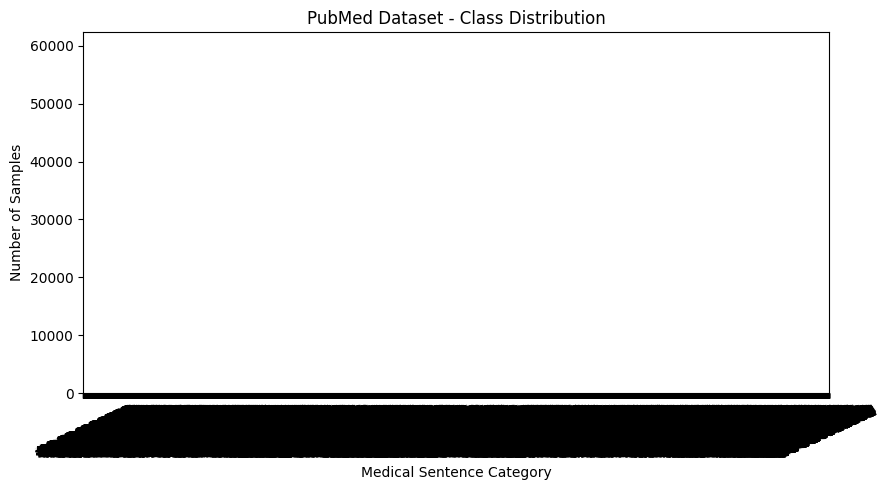

Total samples: 195036
Total classes: 15004


In [3]:

# CELL 3: DATA EXPLORATION AND CLASS DISTRIBUTION

import matplotlib.pyplot as plt
import seaborn as sns

# 1. Count samples for each label
label_counts = df_clean["label_id"].value_counts().sort_index()

distribution = pd.DataFrame({
    "Label ID": label_counts.index,
    "Label": [id2label[i] for i in label_counts.index],
    "Number of Samples": label_counts.values
})

print("Number of samples in each category:")
display(distribution)

# 2. Plot class distribution
plt.figure(figsize=(9, 5))

sns.barplot(
    data=distribution,
    x="Label",
    y="Number of Samples"
)

plt.title("PubMed Dataset - Class Distribution")
plt.xlabel("Medical Sentence Category")
plt.ylabel("Number of Samples")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

# 3. Display total samples
print("Total samples:", len(df_clean))
print("Total classes:", df_clean["label_id"].nunique())


In [4]:

# CELL 4: TRAIN-VALIDATION SPLIT AND TOKENIZATION

!pip -q install transformers accelerate scikit-learn

from sklearn.model_selection import train_test_split
from transformers import AutoTokenizer
from torch.utils.data import Dataset
import torch

# 1. Separate text and labels
texts = df_clean["text"].tolist()
labels = df_clean["label_id"].tolist()

# 2. Split dataset into 80% training and 20% validation
X_train, X_val, y_train, y_val = train_test_split(
    texts,
    labels,
    test_size=0.20,
    random_state=42,
    stratify=labels
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))

# 3. Load pre-trained BERT tokenizer
MODEL_NAME = "bert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# 4. Tokenize training and validation text
MAX_LENGTH = 128

train_encodings = tokenizer(
    X_train,
    truncation=True,
    padding="max_length",
    max_length=MAX_LENGTH,
    return_tensors="pt"
)

val_encodings = tokenizer(
    X_val,
    truncation=True,
    padding="max_length",
    max_length=MAX_LENGTH,
    return_tensors="pt"
)

# 5. Create PyTorch Dataset class
class PubMedDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = torch.tensor(labels, dtype=torch.long)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        item = {
            key: value[index]
            for key, value in self.encodings.items()
        }
        item["labels"] = self.labels[index]
        return item

# 6. Create training and validation datasets
train_dataset = PubMedDataset(train_encodings, y_train)
val_dataset = PubMedDataset(val_encodings, y_val)

print("\nTokenization completed successfully!")
print("Input token shape:", train_encodings["input_ids"].shape)
print("Number of classes:", len(id2label))


ValueError: The least populated class in y has only 1 member, which is too few. The minimum number of groups for any class cannot be less than 2.

In [ ]:

# CELL 5: LOAD PRE-TRAINED BERT MODEL

from transformers import AutoModelForSequenceClassification
import torch

# 1. Set number of output classes
num_labels = len(id2label)

# 2. Create label mappings
label2id = {name: idx for idx, name in id2label.items()}

# 3. Load BERT with classification head
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=num_labels,
    id2label=id2label,
    label2id=label2id
)

# 4. Select GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

print("BERT model loaded successfully!")
print("Model:", MODEL_NAME)
print("Number of classes:", num_labels)
print("Device:", device)
print("\nOutput labels:")
print(id2label)


In [ ]:

# CELL 6: MODEL TRAINING AND VALIDATION

from torch.utils.data import DataLoader
from transformers import get_linear_schedule_with_warmup
from torch.optim import AdamW
from sklearn.metrics import accuracy_score
import torch
import numpy as np

# 1. Set training parameters
BATCH_SIZE = 16
EPOCHS = 3
LEARNING_RATE = 2e-5

# 2. Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# 3. Define optimizer and scheduler
optimizer = AdamW(
    model.parameters(),
    lr=LEARNING_RATE
)

total_steps = len(train_loader) * EPOCHS

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=0,
    num_training_steps=total_steps
)

# 4. Store results for visualization
history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": []
}

# 5. Training loop
for epoch in range(EPOCHS):

    model.train()
    total_train_loss = 0
    train_predictions = []
    train_actual = []

    for batch in train_loader:

        batch = {
            key: value.to(device)
            for key, value in batch.items()
        }

        optimizer.zero_grad()

        outputs = model(**batch)
        loss = outputs.loss

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(), max_norm=1.0
        )

        optimizer.step()
        scheduler.step()

        total_train_loss += loss.item()

        predictions = torch.argmax(
            outputs.logits, dim=1
        )

        train_predictions.extend(predictions.cpu().numpy())
        train_actual.extend(batch["labels"].cpu().numpy())

    avg_train_loss = total_train_loss / len(train_loader)
    train_accuracy = accuracy_score(
        train_actual, train_predictions
    )

    # 6. Validation
    model.eval()
    total_val_loss = 0
    val_predictions = []
    val_actual = []

    with torch.no_grad():
        for batch in val_loader:

            batch = {
                key: value.to(device)
                for key, value in batch.items()
            }

            outputs = model(**batch)

            total_val_loss += outputs.loss.item()

            predictions = torch.argmax(
                outputs.logits, dim=1
            )

            val_predictions.extend(predictions.cpu().numpy())
            val_actual.extend(batch["labels"].cpu().numpy())

    avg_val_loss = total_val_loss / len(val_loader)
    val_accuracy = accuracy_score(
        val_actual, val_predictions
    )

    # 7. Save epoch results
    history["train_loss"].append(avg_train_loss)
    history["val_loss"].append(avg_val_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_accuracy"].append(val_accuracy)

    print(f"\nEpoch {epoch + 1}/{EPOCHS}")
    print(f"Training Loss   : {avg_train_loss:.4f}")
    print(f"Validation Loss : {avg_val_loss:.4f}")
    print(f"Training Accuracy   : {train_accuracy:.4f}")
    print(f"Validation Accuracy : {val_accuracy:.4f}")

print("\nBERT fine-tuning completed successfully!")


In [ ]:

# CELL 7: MODEL EVALUATION

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import torch

# 1. Make predictions on validation dataset
model.eval()

all_predictions = []
all_actual = []

with torch.no_grad():
    for batch in val_loader:

        batch = {
            key: value.to(device)
            for key, value in batch.items()
        }

        outputs = model(**batch)

        predictions = torch.argmax(
            outputs.logits, dim=1
        )

        all_predictions.extend(predictions.cpu().numpy())
        all_actual.extend(batch["labels"].cpu().numpy())

# 2. Calculate evaluation metrics
accuracy = accuracy_score(all_actual, all_predictions)

precision = precision_score(
    all_actual, all_predictions,
    average="weighted", zero_division=0
)

recall = recall_score(
    all_actual, all_predictions,
    average="weighted", zero_division=0
)

f1 = f1_score(
    all_actual, all_predictions,
    average="weighted", zero_division=0
)

print("BERT MODEL PERFORMANCE")
print("------------------------------")
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")

# 3. Classification report
class_ids = sorted(id2label.keys())
class_names = [id2label[i] for i in class_ids]

print("\nClassification Report:")
print(classification_report(
    all_actual,
    all_predictions,
    labels=class_ids,
    target_names=class_names,
    zero_division=0
))

# 4. Generate confusion matrix
cm = confusion_matrix(
    all_actual,
    all_predictions,
    labels=class_ids
)

plt.figure(figsize=(9, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("BERT Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()


In [ ]:

# CELL 8: SHAP EXPLAINABILITY AND TOKEN IMPORTANCE

!pip -q install shap

import shap
import numpy as np
import matplotlib.pyplot as plt
import torch

# 1. Select a sample sentence
sample_text = X_val[0]
actual_label = id2label[y_val[0]]

# 2. Define prediction function for SHAP
def predict_text(texts):
    model.eval()

    inputs = tokenizer(
        list(texts),
        padding=True,
        truncation=True,
        max_length=MAX_LENGTH,
        return_tensors="pt"
    )

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    with torch.no_grad():
        outputs = model(**inputs)
        probabilities = torch.softmax(
            outputs.logits, dim=1
        )

    return probabilities.cpu().numpy()

# 3. Create SHAP text explainer
masker = shap.maskers.Text(tokenizer)

explainer = shap.Explainer(
    predict_text,
    masker,
    output_names=[id2label[i] for i in range(num_labels)]
)

# 4. Calculate SHAP values
shap_values = explainer([sample_text])

# 5. Display prediction
probabilities = predict_text([sample_text])[0]
predicted_id = int(np.argmax(probabilities))

print("Original Sentence:")
print(sample_text)

print("\nActual Label:", actual_label)
print("Predicted Label:", id2label[predicted_id])
print("Prediction Confidence:", round(float(probabilities[predicted_id]) * 100, 2), "%")

# 6. Visualize token-level importance
print("\nSHAP Token-Level Explanation:")

shap.plots.text(shap_values[0, :, predicted_id])


In [ ]:

# CELL 9: ATTENTION HEATMAP AND TRAINING CURVES

import matplotlib.pyplot as plt
import seaborn as sns
import torch
import numpy as np

# ------------------------------------------------
# PART 1: BERT ATTENTION HEATMAP
# ------------------------------------------------

# Select one validation sentence
sample_text = X_val[0]

# Tokenize sentence
inputs = tokenizer(
    sample_text,
    return_tensors="pt",
    truncation=True,
    max_length=MAX_LENGTH
)

inputs = {
    key: value.to(device)
    for key, value in inputs.items()
}

# Enable attention output
model.eval()

with torch.no_grad():
    outputs = model(
        **inputs,
        output_attentions=True
    )

# Get attention from the last layer
# Shape: (number of heads, tokens, tokens)
attention = outputs.attentions[-1][0].mean(dim=0)

# Convert attention into numpy array
attention = attention.cpu().numpy()

# Get actual tokens
tokens = tokenizer.convert_ids_to_tokens(
    inputs["input_ids"][0].cpu().tolist()
)

# Remove padding tokens
valid_length = int(inputs["attention_mask"][0].sum().item())

tokens = tokens[:valid_length]
attention = attention[:valid_length, :valid_length]

# Plot attention heatmap
plt.figure(figsize=(12, 9))

sns.heatmap(
    attention,
    xticklabels=tokens,
    yticklabels=tokens,
    cmap="viridis"
)

plt.title("BERT Attention Heatmap")
plt.xlabel("Tokens")
plt.ylabel("Tokens")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# ------------------------------------------------
# PART 2: TRAINING AND VALIDATION LOSS CURVE
# ------------------------------------------------

epochs = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs,
    history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

# ------------------------------------------------
# PART 3: TRAINING AND VALIDATION ACCURACY CURVE
# ------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history["train_accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs,
    history["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

print("All visualizations generated successfully!")
